# 02 Procesamiento de texto, recuperación secuencial e indexación
- **Estudiante**: Jose Luis Andino
- **Fecha de Entrega:** Miercoles 28 de Octubre del 2026
- **Curso:** GR1CC
- **Carrera:** Computación
- **Docente:** Prof. Iván Carrera

## Objetivo

Implementar y comparar dos mecanismos de recuperación de información —búsqueda secuencial e índice invertido— sobre colecciones de libros del Proyecto Gutenberg, investigando experimentalmente su rendimiento y escalabilidad.

### Parte A. Corpus pequeño

**1. Preparación del corpus**

Utilice los 18 documentos de la colección Gutenberg disponible en NLTK.

1. Cargue los textos originales.
2. Identifique el número de documentos y sus tamaños.
3. Implemente tokenización y normalización: conversión a minúsculas, tratamiento de puntuación y caracteres especiales.

Seleccione y documente una configuración de preprocesamiento que se utilizará consistentemente en todos los experimentos.

In [2]:
# ============ Celda 1: Preparación del corpus (Parte A.1) ============
import re
import sys
import time
import statistics
import unicodedata
from abc import ABC, abstractmethod
from collections import defaultdict
from dataclasses import dataclass
from itertools import islice
from pathlib import Path

import matplotlib.pyplot as plt
import nltk
import numpy as np
import pandas as pd
import psutil
from nltk.corpus import gutenberg

nltk.download("gutenberg", quiet=True)


class TextNormalizer:
    """Configuración única: minúsculas -> NFKD sin diacríticos -> tokens [a-z0-9]+ (sin puntuación)."""
    _TOKEN_RE = re.compile(r"[a-z0-9]+")

    def normalize(self, text: str) -> str:
        text = unicodedata.normalize("NFKD", text.lower())
        return text.encode("ascii", "ignore").decode("ascii")

    def tokenize(self, text: str) -> list[str]:
        # sys.intern evita duplicar strings en memoria (clave en el corpus grande)
        return [sys.intern(t) for t in self._TOKEN_RE.findall(self.normalize(text))]

    def normalize_term(self, term: str) -> str:
        tokens = self._TOKEN_RE.findall(self.normalize(term))
        return tokens[0] if tokens else ""


@dataclass
class Corpus:
    tokens: dict          # doc_id -> list[str]
    raw_chars: dict       # doc_id -> int

    @property
    def n_docs(self) -> int:
        return len(self.tokens)

    @property
    def n_tokens(self) -> int:
        return sum(len(t) for t in self.tokens.values())

    def subset(self, n: int) -> "Corpus":
        ids = list(islice(self.tokens, n))
        return Corpus({i: self.tokens[i] for i in ids}, {i: self.raw_chars[i] for i in ids})


class CorpusSource(ABC):
    @abstractmethod
    def raw_documents(self):
        """Genera tuplas (doc_id, texto_crudo)."""


class NLTKGutenbergSource(CorpusSource):
    def raw_documents(self):
        for file_id in gutenberg.fileids():
            yield file_id, gutenberg.raw(file_id)


class DirectorySource(CorpusSource):
    """Lee archivos '<id>.txt' (id original de Gutenberg) ordenados numéricamente."""
    _START, _END = "*** START OF", "*** END OF"

    def __init__(self, directory: Path, limit: int | None = None):
        self._directory = Path(directory)
        self._limit = limit

    def raw_documents(self):
        paths = sorted(self._directory.glob("*.txt"), key=lambda p: int(p.stem))
        for path in paths[: self._limit]:
            yield int(path.stem), self._strip_boilerplate(path.read_text(encoding="utf-8", errors="ignore"))

    def _strip_boilerplate(self, text: str) -> str:
        start = text.find(self._START)
        if start != -1:
            start = text.find("\n", start)
            text = text[start + 1:] if start != -1 else text
        end = text.find(self._END)
        return text[:end] if end != -1 else text


class CorpusBuilder:
    def __init__(self, normalizer: TextNormalizer):
        self._normalizer = normalizer

    def build(self, source: CorpusSource) -> Corpus:
        tokens, sizes = {}, {}
        for doc_id, raw in source.raw_documents():
            tokens[doc_id] = self._normalizer.tokenize(raw)
            sizes[doc_id] = len(raw)
        return Corpus(tokens, sizes)


normalizer = TextNormalizer()
corpus = CorpusBuilder(normalizer).build(NLTKGutenbergSource())

summary = pd.DataFrame({
    "doc_id": list(corpus.tokens),
    "caracteres": list(corpus.raw_chars.values()),
    "tokens": [len(t) for t in corpus.tokens.values()],
})
print(f"Documentos: {corpus.n_docs} | Tokens totales: {corpus.n_tokens:,}")
summary

Documentos: 18 | Tokens totales: 2,199,207


,doc_id,caracteres,tokens
0,austen-emma.txt,887071,161980
1,austen-persuasion.txt,466292,84167
2,austen-sense.txt,673022,120787
3,bible-kjv.txt,4332554,854046
4,blake-poems.txt,38153,6936
5,bryant-stories.txt,249439,46699
6,burgess-busterbrown.txt,84663,16359
7,carroll-alice.txt,144395,27336
8,chesterton-ball.txt,457450,82865
9,chesterton-brown.txt,406629,73288


**2. Búsqueda secuencial**

Implemente una función que reciba un término de consulta y devuelva los identificadores de todos los documentos que lo contienen con una búsqueda secuencial.

La implementación deberá utilizar obligatoriamente dos lazos `for` anidados: el primero recorre los documentos y el segundo los tokens de cada documento.

No es necesario utilizar índices invertidos, motores de búsqueda ni estructuras auxiliares que almacenen anticipadamente los documentos asociados a cada término.

Ejecute consultas con términos frecuentes, poco frecuentes e inexistentes.

In [3]:
# ============ Celda 2: Búsqueda secuencial (Parte A.2) ============
class Searcher(ABC):
    @abstractmethod
    def search(self, term: str) -> list:
        """Ids de documentos que contienen el término (ya normalizado)."""

    @abstractmethod
    def doc_ids(self) -> list:
        """Universo de documentos (necesario para NOT)."""


class SequentialSearcher(Searcher):
    def __init__(self, corpus: Corpus):
        self._tokens = corpus.tokens

    def search(self, term: str) -> list:
        result = []
        for doc_id, tokens in self._tokens.items():
            for token in tokens:
                if token == term:
                    result.append(doc_id)
                    break
        return result

    def doc_ids(self) -> list:
        return list(self._tokens)


seq = SequentialSearcher(corpus)
for label, term in [("frecuente", "the"), ("poco frecuente", "ahab"), ("inexistente", "zxqwv")]:
    found = seq.search(normalizer.normalize_term(term))
    print(f"{label:15} '{term}': {len(found)} docs -> {found[:5]}")

frecuente       'the': 18 docs -> ['austen-emma.txt', 'austen-persuasion.txt', 'austen-sense.txt', 'bible-kjv.txt', 'blake-poems.txt']
poco frecuente  'ahab': 2 docs -> ['bible-kjv.txt', 'melville-moby_dick.txt']
inexistente     'zxqwv': 0 docs -> []


**3. Medición de tiempos de ejecución**

Utilice `time.perf_counter_ns()` o una herramienta de medición equivalente para obtener el tiempo de ejecución de las consultas.

Cada medición deberá corresponder a **30 ejecuciones de la misma consulta**. Y se debe calcular la media aritmética.

Registre los resultados en milisegundos. No incluya la carga de archivos ni la tokenización dentro del tiempo de consulta.

In [4]:
# ============ Celda 3: Medición de tiempos (Parte A.3) ============
RUNS = 30


def mean_time_ms(fn, runs: int = RUNS) -> float:
    """Media aritmética (ms) de `runs` ejecuciones de fn(). Solo mide la consulta."""
    times = []
    for _ in range(runs):
        t0 = time.perf_counter_ns()
        fn()
        times.append(time.perf_counter_ns() - t0)
    return statistics.mean(times) / 1e6


rows = []
for label, term in [("frecuente", "the"), ("poco frecuente", "ahab"), ("inexistente", "zxqwv")]:
    t = normalizer.normalize_term(term)
    rows.append({"consulta": label, "termino": term, "secuencial_ms": mean_time_ms(lambda: seq.search(t))})
pd.DataFrame(rows)

,consulta,termino,secuencial_ms
0,frecuente,the,0.009440
1,poco frecuente,ahab,39.547920
2,inexistente,zxqwv,56.759953


**4. Construcción del índice invertido**

Implemente un índice invertido que contenga el vocabulario de la colección y las listas de documentos asociados a cada término.

Inspeccione las listas de postings y calcule la frecuencia documental (DF) de varios términos.

Implemente consultas de un término y consultas booleanas con AND, OR y NOT.

In [5]:
# ============ Celda 4: Índice invertido y consultas booleanas (Parte A.4) ============
class InvertedIndex(Searcher):
    def __init__(self, postings: dict, all_ids: list):
        self._postings = postings
        self._all_ids = all_ids

    @classmethod
    def build(cls, corpus: Corpus) -> "InvertedIndex":
        sets = defaultdict(set)
        for doc_id, tokens in corpus.tokens.items():
            for token in set(tokens):
                sets[token].add(doc_id)
        postings = {term: sorted(ids) for term, ids in sets.items()}
        return cls(postings, list(corpus.tokens))

    def search(self, term: str) -> list:
        return self._postings.get(term, [])

    def doc_ids(self) -> list:
        return self._all_ids

    def df(self, term: str) -> int:
        return len(self._postings.get(term, []))

    @property
    def vocabulary_size(self) -> int:
        return len(self._postings)


@dataclass(frozen=True)
class QuerySpec:
    label: str
    op: str            # "term" | "and" | "or" | "not"
    terms: tuple


class QueryEngine:
    """Consultas booleanas sobre cualquier Searcher (secuencial o índice)."""

    def __init__(self, searcher: Searcher, normalizer: TextNormalizer):
        self._searcher = searcher
        self._normalizer = normalizer

    def _docs(self, term: str) -> set:
        return set(self._searcher.search(self._normalizer.normalize_term(term)))

    def term(self, t: str) -> list:
        return sorted(self._docs(t))

    def and_(self, *terms: str) -> list:
        sets = [self._docs(t) for t in terms]
        return sorted(set.intersection(*sets))

    def or_(self, *terms: str) -> list:
        return sorted(set.union(*(self._docs(t) for t in terms)))

    def not_(self, t: str) -> list:
        return sorted(set(self._searcher.doc_ids()) - self._docs(t))

    def run(self, spec: QuerySpec) -> list:
        ops = {"term": self.term, "and": self.and_, "or": self.or_, "not": self.not_}
        return ops[spec.op](*spec.terms)


index = InvertedIndex.build(corpus)
print(f"Vocabulario: {index.vocabulary_size:,} términos")
for t in ["the", "whale", "ahab", "zxqwv"]:
    print(f"{t:8} DF={index.df(t):3} postings={index.search(t)}")

engine_idx = QueryEngine(index, normalizer)
print("whale AND sea  :", engine_idx.and_("whale", "sea"))
print("whale OR caesar:", engine_idx.or_("whale", "caesar"))
print("NOT whale      :", engine_idx.not_("whale"))

Vocabulario: 41,838 términos
the      DF= 18 postings=['austen-emma.txt', 'austen-persuasion.txt', 'austen-sense.txt', 'bible-kjv.txt', 'blake-poems.txt', 'bryant-stories.txt', 'burgess-busterbrown.txt', 'carroll-alice.txt', 'chesterton-ball.txt', 'chesterton-brown.txt', 'chesterton-thursday.txt', 'edgeworth-parents.txt', 'melville-moby_dick.txt', 'milton-paradise.txt', 'shakespeare-caesar.txt', 'shakespeare-hamlet.txt', 'shakespeare-macbeth.txt', 'whitman-leaves.txt']
whale    DF=  6 postings=['bible-kjv.txt', 'bryant-stories.txt', 'chesterton-ball.txt', 'melville-moby_dick.txt', 'shakespeare-hamlet.txt', 'whitman-leaves.txt']
ahab     DF=  2 postings=['bible-kjv.txt', 'melville-moby_dick.txt']
zxqwv    DF=  0 postings=[]
whale AND sea  : ['bible-kjv.txt', 'bryant-stories.txt', 'chesterton-ball.txt', 'melville-moby_dick.txt', 'shakespeare-hamlet.txt', 'whitman-leaves.txt']
whale OR caesar: ['bible-kjv.txt', 'bryant-stories.txt', 'chesterton-ball.txt', 'chesterton-brown.txt', 'chestert

**5. Comparación**

Ejecute las mismas consultas con ambos métodos.

Compruebe que recuperan exactamente los mismos identificadores de documentos y mida el tiempo medio de 30 ejecuciones para cada consulta y método.

In [6]:
# ============ Celda 5: Comparación (Parte A.5) ============
QUERIES = [
    QuerySpec("frecuente", "term", ("the",)),
    QuerySpec("poco frecuente", "term", ("ahab",)),
    QuerySpec("inexistente", "term", ("zxqwv",)),
    QuerySpec("AND", "and", ("whale", "sea")),
    QuerySpec("OR", "or", ("whale", "caesar")),
    QuerySpec("NOT", "not", ("whale",)),
]


def compare_engines(engines: dict, queries: list, runs: int = RUNS) -> pd.DataFrame:
    rows = []
    for spec in queries:
        results = {name: eng.run(spec) for name, eng in engines.items()}
        first = next(iter(results.values()))
        row = {
            "consulta": spec.label,
            "terminos": " ".join(spec.terms),
            "n_resultados": len(first),
            "resultados_iguales": all(r == first for r in results.values()),
        }
        for name, eng in engines.items():
            row[f"{name}_ms"] = mean_time_ms(lambda e=eng: e.run(spec), runs)
        row["speedup"] = row["secuencial_ms"] / row["indice_ms"] if row["indice_ms"] else float("inf")
        rows.append(row)
    return pd.DataFrame(rows)


engines_a = {
    "secuencial": QueryEngine(SequentialSearcher(corpus), normalizer),
    "indice": QueryEngine(index, normalizer),
}
compare_engines(engines_a, QUERIES)

,consulta,terminos,n_resultados,resultados_iguales,secuencial_ms,indice_ms,speedup
0,frecuente,the,18,True,0.009617,0.002407,3.995845
1,poco frecuente,ahab,2,True,39.760543,0.003707,10726.765288
2,inexistente,zxqwv,0,True,57.298970,0.002053,27905.342532
3,AND,whale sea,6,True,39.796240,0.003970,10024.241814
4,OR,whale caesar,11,True,76.074313,0.004543,16744.162876
5,NOT,whale,12,True,32.427617,0.003590,9032.762303


### Parte B. Corpus grande

**6. Descarga de Gutenberg**

Descargue el archivo oficial `txt-files.tar.zip`, de aproximadamente 11 GB, desde:

https://www.gutenberg.org/cache/epub/feeds/

Identifique los archivos TXT, evite contar distintas versiones del mismo libro como documentos independientes y registre la cantidad de documentos válidos.

In [8]:
# ============ Celda 6: Corpus grande desde ./data en la raíz (Parte B.6) ============
import tarfile
import zipfile
from contextlib import contextmanager
from pathlib import Path


def find_project_root(marker: str = "pyproject.toml") -> Path:
    start = Path.cwd().resolve()
    for folder in (start, *start.parents):
        if (folder / marker).exists():
            return folder
    raise FileNotFoundError(f"No se encontró '{marker}' subiendo desde {start}")


PROJECT_ROOT = find_project_root()
DATA_DIR = PROJECT_ROOT / "data"
ARCHIVE_PATH = next(DATA_DIR.glob("txt-files.tar*"), None)   # acepta .tar.zip o .tar
if ARCHIVE_PATH is None:
    raise FileNotFoundError(f"Coloca txt-files.tar.zip en {DATA_DIR}")

SUBSET_DIR = DATA_DIR / "subset"
MAX_SAVED_DOCS = 1000       # documentos a extraer a disco para los experimentos
COUNT_ALL = True            # True: recorre todo el archivo para contar libros válidos (lento)
BOOK_FILE_RE = re.compile(r"^pg(\d+)(?:[-_][\w-]*)?\.txt$")


class GutenbergArchiveScanner:
    """Recorre el .tar en streaming; conserva una sola versión por id de libro."""

    def __init__(self, archive_path: Path, out_dir: Path, max_saved: int, count_all: bool):
        self._archive_path, self._out_dir = Path(archive_path), Path(out_dir)
        self._max_saved, self._count_all = max_saved, count_all

    @contextmanager
    def _open_tar_stream(self):
        if self._archive_path.suffix == ".zip":
            with zipfile.ZipFile(self._archive_path) as zf:
                inner = next(n for n in zf.namelist() if n.endswith(".tar"))
                with zf.open(inner) as raw:
                    yield raw
        else:
            with open(self._archive_path, "rb") as raw:
                yield raw

    def _iter_books(self):
        with self._open_tar_stream() as raw, tarfile.open(fileobj=raw, mode="r|") as tar:
            for member in tar:
                match = BOOK_FILE_RE.match(Path(member.name).name) if member.isfile() else None
                if match:
                    yield int(match.group(1)), lambda m=member: tar.extractfile(m).read()

    def scan(self) -> dict:
        self._out_dir.mkdir(parents=True, exist_ok=True)
        seen, saved = set(), 0
        for book_id, read in self._iter_books():
            if book_id in seen:
                continue
            seen.add(book_id)
            if saved < self._max_saved:
                (self._out_dir / f"{book_id}.txt").write_bytes(read())
                saved += 1
            elif not self._count_all:
                break
        return {"documentos_validos": len(seen), "guardados": saved}


print(f"Archivo: {ARCHIVE_PATH} ({ARCHIVE_PATH.stat().st_size / 2**30:.2f} GB)")
scan_result = GutenbergArchiveScanner(ARCHIVE_PATH, SUBSET_DIR, MAX_SAVED_DOCS, COUNT_ALL).scan()
print(scan_result)

Archivo: C:\Users\TheAn\Desktop\COMPUTACION 09\Recuperacion de la Informacion\Notebook\data\txt-files.tar.zip (10.55 GB)
{'documentos_validos': 78145, 'guardados': 1000}


**7. Recuperación sobre el corpus grande**

Reutilice las funciones desarrolladas en la Parte A.

1. Procese los documentos con la misma configuración de normalización.
2. Ejecute las consultas mediante búsqueda secuencial y mida los tiempos.
3. Construya el índice invertido.
4. Repita las consultas utilizando el índice.
5. Compruebe la igualdad de resultados y compare los tiempos.

Trabaje con subconjuntos de la colección de tamaños crecientes, conservando los identificadores originales. Documente los recursos de memoria y almacenamiento utilizados.

In [9]:
# ============ Celda 7: Recuperación sobre el corpus grande (Parte B.7) ============
@dataclass
class BuildStats:
    build_s: float
    rss_delta_mb: float


def rss_mb() -> float:
    return psutil.Process().memory_info().rss / 2**20


def build_engines(corpus: Corpus):
    """Construye ambos motores y mide tiempo y memoria (RSS) de construcción del índice."""
    rss0, t0 = rss_mb(), time.perf_counter()
    index = InvertedIndex.build(corpus)
    stats = BuildStats(time.perf_counter() - t0, rss_mb() - rss0)
    engines = {
        "secuencial": QueryEngine(SequentialSearcher(corpus), normalizer),
        "indice": QueryEngine(index, normalizer),
    }
    return engines, index, stats


rss_before = rss_mb()
full_corpus = CorpusBuilder(normalizer).build(DirectorySource(SUBSET_DIR, limit=MAX_SAVED_DOCS))
print(f"Corpus cargado: {full_corpus.n_docs} docs, {full_corpus.n_tokens:,} tokens, "
      f"RSS +{rss_mb() - rss_before:.0f} MB")

SIZES_B = [100, 500, 1000]
resources, comparisons = [], []
for n in SIZES_B:
    sub = full_corpus.subset(n)
    engines, idx, stats = build_engines(sub)
    resources.append({
        "n_docs": sub.n_docs,
        "n_tokens": sub.n_tokens,
        "vocabulario": idx.vocabulary_size,
        "build_indice_s": stats.build_s,
        "memoria_indice_mb": stats.rss_delta_mb,
        "texto_mb": sum(sub.raw_chars.values()) / 2**20,
    })
    cmp_df = compare_engines(engines, QUERIES)
    cmp_df.insert(0, "n_docs", n)
    comparisons.append(cmp_df)

display(pd.DataFrame(resources))
display(pd.concat(comparisons, ignore_index=True))

Corpus cargado: 1000 docs, 69,919,109 tokens, RSS +622 MB


,n_docs,n_tokens,vocabulario,build_indice_s,memoria_indice_mb,texto_mb
0,100,8096371,113305,2.078794,35.281250,42.746513
1,500,35172701,405427,5.848778,65.894531,189.261686
2,1000,69919109,653887,10.245393,124.070312,378.010532


,n_docs,consulta,terminos,n_resultados,resultados_iguales,secuencial_ms,indice_ms,speedup
0,100,frecuente,the,97,True,7.628557,0.005817,1311.499713
1,100,poco frecuente,ahab,1,True,230.783330,0.002247,102722.550445
2,100,inexistente,zxqwv,0,True,231.879373,0.002047,113296.110749
3,100,AND,whale sea,15,True,232.658963,0.006160,37769.312229
4,100,OR,whale caesar,31,True,366.290830,0.005667,64639.558235
5,100,NOT,whale,84,True,184.739903,0.007487,24675.855298
6,500,frecuente,the,481,True,33.981183,0.015453,2198.954918
7,500,poco frecuente,ahab,9,True,1114.309977,0.002547,437556.273560
8,500,inexistente,zxqwv,0,True,1103.552887,0.002107,523838.395570
9,500,AND,whale sea,72,True,1214.154963,0.015700,77334.711040


### Parte C. Análisis experimental de escalabilidad

**8. Tiempo de ejecución en función del corpus**

Seleccione al menos cinco tamaños crecientes del corpus grande. Como referencia, pueden utilizarse 50, 100, 250, 500 y 1.000 documentos, ampliándolos si el equipo lo permite.

Para cada tamaño $n$:

1. Ejecute una misma consulta mediante búsqueda secuencial.
2. Repítala 30 veces y calcule el tiempo promedio.
3. Construya el índice invertido correspondiente a ese subconjunto.
4. Ejecute la consulta mediante el índice, también 30 veces.
5. Registre ambos tiempos y el número total de tokens.

Elabore una **gráfica del tiempo medio de ejecución en función del número de documentos**, colocando el número de documentos en el eje X y el tiempo en milisegundos en el eje Y. Represente los dos métodos en la misma gráfica.

,n_docs,n_tokens,secuencial_ms,indice_ms,build_indice_s
0,50,5065205,92.767237,0.002643,0.382671
1,100,8096371,177.181263,0.002737,0.679051
2,250,17766954,432.836400,0.003673,2.328403
3,500,35172701,926.749687,0.005177,5.308352
4,1000,69919109,1753.625410,0.008207,8.473095


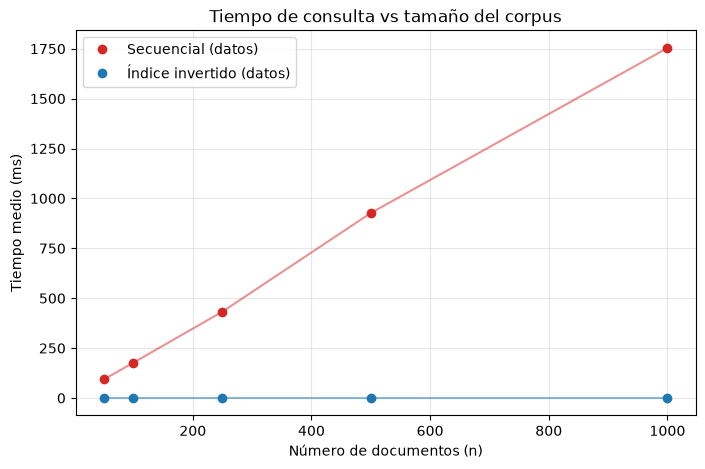

In [11]:
# ============ Celda 8: Tiempo en función del corpus (Parte C.8) ============
SIZES_C = [50, 100, 250, 500, 1000]
SCALE_QUERY = QuerySpec("escalabilidad", "term", ("whale",))


def scalability_experiment(corpus: Corpus, sizes: list, spec: QuerySpec, runs: int = RUNS) -> pd.DataFrame:
    rows = []
    for n in sizes:
        sub = corpus.subset(n)
        engines, _, stats = build_engines(sub)
        assert engines["secuencial"].run(spec) == engines["indice"].run(spec)
        rows.append({
            "n_docs": sub.n_docs,
            "n_tokens": sub.n_tokens,
            "secuencial_ms": mean_time_ms(lambda: engines["secuencial"].run(spec), runs),
            "indice_ms": mean_time_ms(lambda: engines["indice"].run(spec), runs),
            "build_indice_s": stats.build_s,
        })
    return pd.DataFrame(rows)


def plot_scalability(df: pd.DataFrame, fits: dict | None = None, log_y: bool = False) -> None:
    fig, ax = plt.subplots(figsize=(8, 5))
    for col, label, color in [("secuencial_ms", "Secuencial", "tab:red"), ("indice_ms", "Índice invertido", "tab:blue")]:
        ax.plot(df["n_docs"], df[col], "o", color=color, label=f"{label} (datos)")
        if fits:
            a, b, r2 = fits[col]
            xs = np.linspace(df["n_docs"].min(), df["n_docs"].max(), 100)
            ax.plot(xs, a * xs + b, "--", color=color, label=f"{label}: t={a:.3g}n+{b:.3g} (R²={r2:.4f})")
        else:
            ax.plot(df["n_docs"], df[col], "-", color=color, alpha=0.5)
    ax.set_xlabel("Número de documentos (n)")
    ax.set_ylabel("Tiempo medio (ms)")
    ax.set_title("Tiempo de consulta vs tamaño del corpus")
    if log_y:
        ax.set_yscale("log")
    ax.grid(alpha=0.3)
    ax.legend()
    plt.show()


scale_df = scalability_experiment(full_corpus, SIZES_C, SCALE_QUERY)
display(scale_df)
plot_scalability(scale_df)

**9. Estimación de una función de tiempo**

Utilizando los resultados experimentales, determine una función:

$t=f(n)$

para cada método de recuperación.

Como primera aproximación, utilice un ajuste lineal por mínimos cuadrados:

$t(n)=an+b$

Estime los parámetros $a$ y $b$, reporte el coeficiente de determinación $R^2$ y represente las funciones ajustadas junto a los datos experimentales.

Explique si el modelo lineal representa adecuadamente las mediciones y cómo se relaciona con la complejidad computacional de cada algoritmo.

,a (ms/doc),b (ms),R²
secuencial_ms,1.761136,7.400297,0.998935
indice_ms,0.000006,0.002223,0.998854


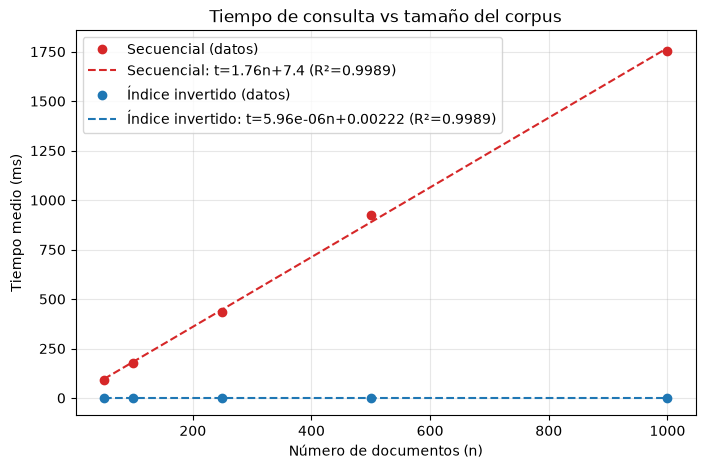

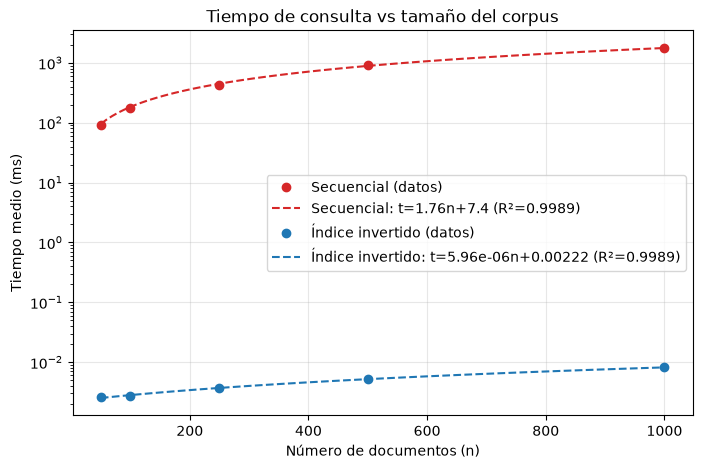

In [12]:
# ============ Celda 9: Ajuste t = f(n) (Parte C.9) ============
def fit_linear(x: np.ndarray, y: np.ndarray) -> tuple:
    """Mínimos cuadrados t = a*n + b y R²."""
    a, b = np.polyfit(x, y, 1)
    ss_res = np.sum((y - (a * x + b)) ** 2)
    ss_tot = np.sum((y - y.mean()) ** 2)
    r2 = 1 - ss_res / ss_tot if ss_tot else 1.0
    return float(a), float(b), float(r2)


x = scale_df["n_docs"].to_numpy(dtype=float)
fits = {col: fit_linear(x, scale_df[col].to_numpy()) for col in ["secuencial_ms", "indice_ms"]}

display(pd.DataFrame(fits, index=["a (ms/doc)", "b (ms)", "R²"]).T)
plot_scalability(scale_df, fits=fits)
plot_scalability(scale_df, fits=fits, log_y=True)